# Import

In [18]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import os
from pathlib import Path
from PIL import Image

In [20]:
DRIVE_BASE = Path('/content/drive/My Drive/bangla_evaluation')

IMAGE_DIR = "/content/drive/MyDrive/images"
CSV_PATH = "/content/drive/MyDrive/labels.csv"

CHECKPOINT_DIR = DRIVE_BASE / 'checkpoints'
RESULTS_DIR = DRIVE_BASE / 'results'

for d in [DRIVE_BASE, CHECKPOINT_DIR, RESULTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f'Drive ready at: {DRIVE_BASE}')

Drive ready at: /content/drive/My Drive/bangla_evaluation


# EDA and Preprocessing

In [21]:

df = pd.read_csv(CSV_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (172, 2)

Columns:
['Image Name', 'Ground Truth']


,Image Name,Ground Truth
0,image001.jpg,MDG এর ৪ টি লক্ষ্য -\n1. চরম দারিদ্র্য ও ক্ষুধ...
1,image002.jpg,"তোমাদের মধ্যে সর্বোত্তম ঐ ব্যাক্তি, যে কুরআন \..."
2,image003.jpg,ব্যবস্থাপনার নীতিমালা - প্রফেসর এ. কে চৌধুরী \...
3,image004.jpg,হিশাম হিশাম\nহিশাম হিশাম\nহিশাম ...
4,image005.jpg,পাইনএপল জুস\nউপকরণঃ-\nপাইনএপল ১ টা লেবুর রস \n...


In [22]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate image names:",
      df["Image Name"].duplicated().sum())

Missing values:
Image Name      0
Ground Truth    0
dtype: int64

Duplicate rows: 0

Duplicate image names: 0


In [23]:
df["image_path"] = df["Image Name"].apply(
    lambda x: os.path.join(IMAGE_DIR, x)
)

df["exists"] = df["image_path"].apply(os.path.exists)

print("Images found:", df["exists"].sum())
print("Images missing:", (~df["exists"]).sum())

Images found: 170
Images missing: 2


Average characters: 241.5174418604651
Minimum characters: 51
Maximum characters: 953
Average words: 39.19186046511628


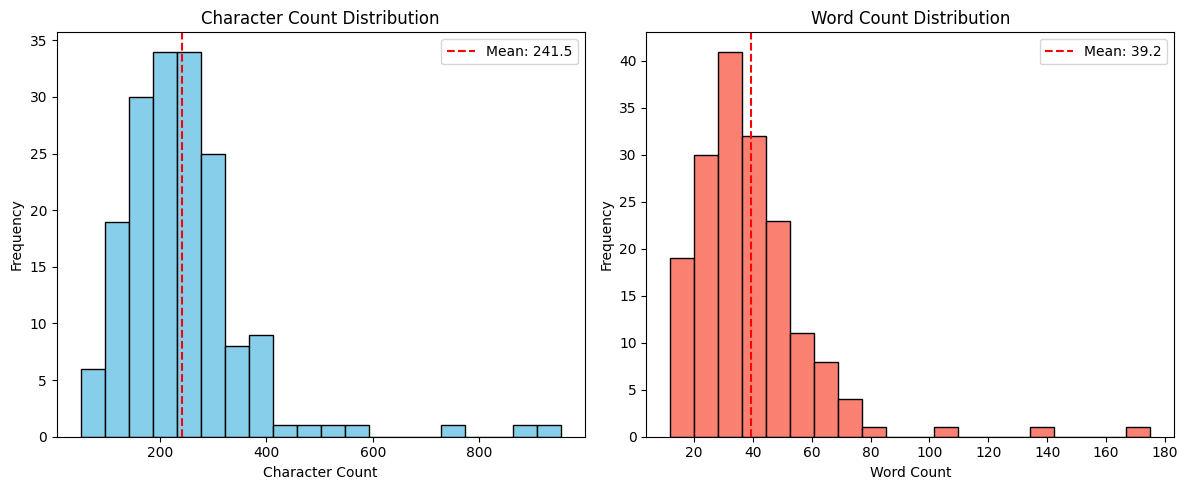

In [24]:
df["Ground Truth"] = df["Ground Truth"].fillna("").astype(str)

df["char_count"] = df["Ground Truth"].str.len()

df["word_count"] = df["Ground Truth"].str.split().str.len()

print("Average characters:",
      df["char_count"].mean())

print("Minimum characters:",
      df["char_count"].min())

print("Maximum characters:",
      df["char_count"].max())

print("Average words:",
      df["word_count"].mean())

# Create a figure with 2 side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Character count histogram
axes[0].hist(df["char_count"], bins=20, color="skyblue", edgecolor="black")
axes[0].set_title("Character Count Distribution")
axes[0].set_xlabel("Character Count")
axes[0].set_ylabel("Frequency")
axes[0].axvline(
    df["char_count"].mean(),
    color="red",
    linestyle="dashed",
    linewidth=1.5,
    label=f"Mean: {df['char_count'].mean():.1f}",
)
axes[0].legend()

# Word count histogram
axes[1].hist(df["word_count"], bins=20, color="salmon", edgecolor="black")
axes[1].set_title("Word Count Distribution")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Frequency")
axes[1].axvline(
    df["word_count"].mean(),
    color="red",
    linestyle="dashed",
    linewidth=1.5,
    label=f"Mean: {df['word_count'].mean():.1f}",
)
axes[1].legend()

plt.tight_layout()
plt.show()

In [25]:
import re
from collections import Counter

all_text = "".join(df["Ground Truth"])

bangla_chars = re.findall(r'[\u0980-\u09FF]', all_text)

print("Total Bangla characters:", len(bangla_chars))

char_counts = Counter(bangla_chars)

print("\nMost common Bangla characters:")
print(char_counts.most_common(20))

Total Bangla characters: 32592

Most common Bangla characters:
[('া', 3321), ('র', 2444), ('্', 2319), ('ে', 2299), ('ন', 1652), ('ি', 1641), ('য', 1567), ('ক', 1546), ('ব', 1357), ('ত', 1116), ('ম', 1055), ('প', 1018), ('স', 923), ('দ', 780), ('়', 777), ('ল', 721), ('হ', 501), ('ো', 431), ('ু', 428), ('শ', 416)]


In [26]:
path = "/content/drive/MyDrive/images/image005.jpg"

print("Exists:", os.path.exists(path))
print("Size:", os.path.getsize(path), "bytes")

try:
    with Image.open(path) as img:
        print("Format:", img.format)
        print("Dimensions:", img.size)
except Exception as e:
    print("Error:", e)

Exists: True
Size: 2990327 bytes
Error: cannot identify image file '/content/drive/MyDrive/images/image005.jpg'


In [27]:
# Only keeping good pictures

valid_files = []
bad_files = []

for path in df.loc[df["exists"], "image_path"]:
    try:
        with Image.open(path) as img:
            img.verify()

        valid_files.append(path)

    except Exception as e:
        bad_files.append({
            "path": path,
            "error": str(e)
        })

# Keep only rows with valid images
df = df[df["image_path"].isin(valid_files)].copy()

print("Valid images:", len(valid_files))
print("Bad images:", len(bad_files))
print("Final dataframe:", len(df))

# images that are removed
display(pd.DataFrame(bad_files))

Valid images: 162
Bad images: 8
Final dataframe: 162


,path,error
0,/content/drive/MyDrive/images/image005.jpg,cannot identify image file '/content/drive/MyD...
1,/content/drive/MyDrive/images/image006.jpg,cannot identify image file '/content/drive/MyD...
2,/content/drive/MyDrive/images/image007.jpg,cannot identify image file '/content/drive/MyD...
3,/content/drive/MyDrive/images/image008.jpg,cannot identify image file '/content/drive/MyD...
4,/content/drive/MyDrive/images/image058.jpg,cannot identify image file '/content/drive/MyD...
5,/content/drive/MyDrive/images/image059.jpg,cannot identify image file '/content/drive/MyD...
6,/content/drive/MyDrive/images/image060.jpg,cannot identify image file '/content/drive/MyD...
7,/content/drive/MyDrive/images/image062.jpg,cannot identify image file '/content/drive/MyD...


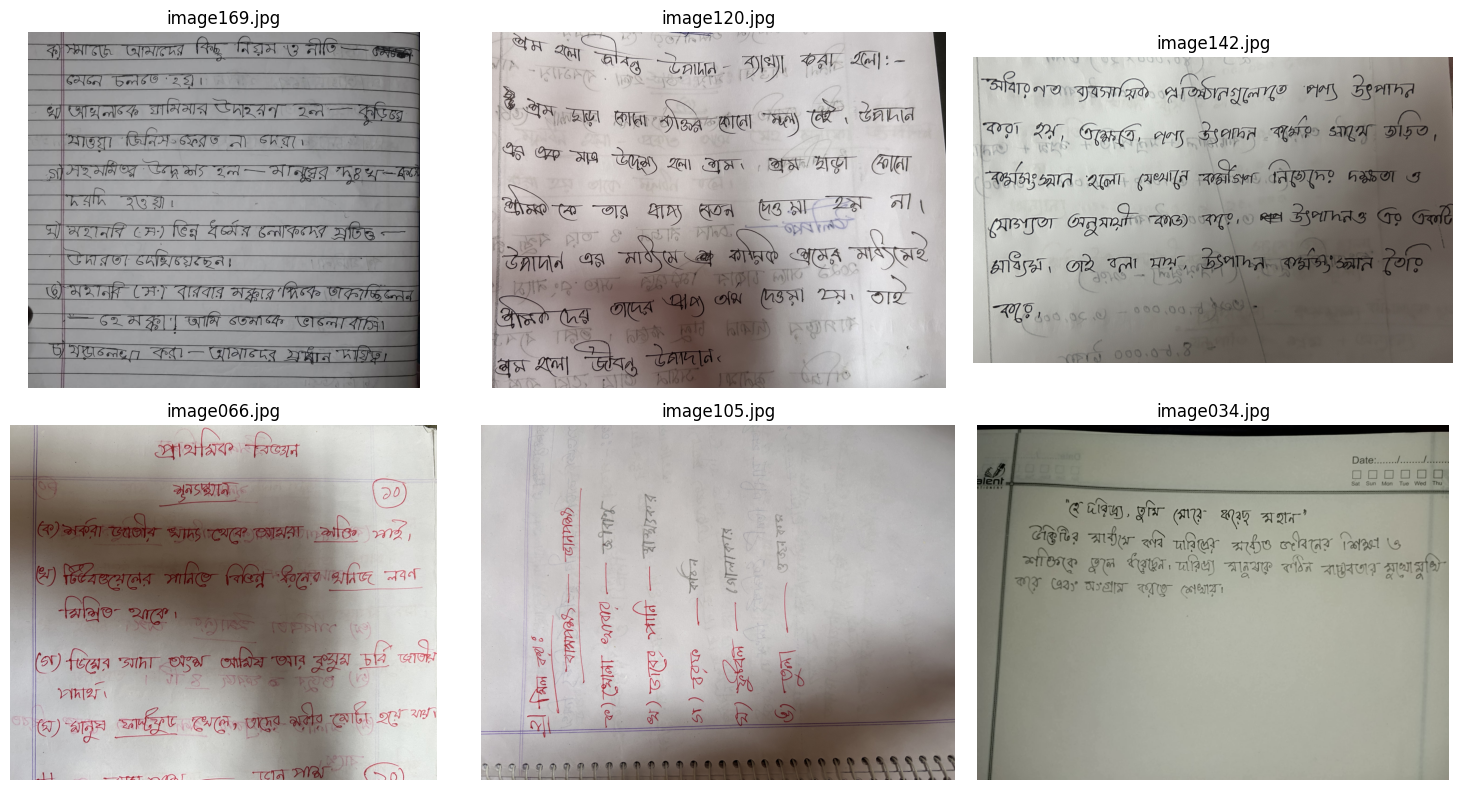

In [28]:
sample = df[df["exists"]].sample(6, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    img = Image.open(row["image_path"])

    ax.imshow(img)
    ax.set_title(row["Image Name"])
    ax.axis("off")

plt.tight_layout()
plt.show()

# MAIN

In [29]:
df

,Image Name,Ground Truth,image_path,exists,char_count,word_count
0,image001.jpg,MDG এর ৪ টি লক্ষ্য -\n1. চরম দারিদ্র্য ও ক্ষুধ...,/content/drive/MyDrive/images/image001.jpg,True,310,51
1,image002.jpg,"তোমাদের মধ্যে সর্বোত্তম ঐ ব্যাক্তি, যে কুরআন \...",/content/drive/MyDrive/images/image002.jpg,True,107,17
2,image003.jpg,ব্যবস্থাপনার নীতিমালা - প্রফেসর এ. কে চৌধুরী \...,/content/drive/MyDrive/images/image003.jpg,True,312,45
3,image004.jpg,হিশাম হিশাম\nহিশাম হিশাম\nহিশাম ...,/content/drive/MyDrive/images/image004.jpg,True,202,18
8,image009.jpg,"ইউনিভার্সিটিতে আসার পর বুঝেছি, ক্লাসে অ্যাটেনড...",/content/drive/MyDrive/images/image009.jpg,True,317,55
...,...,...,...,...,...,...
167,image168.jpg,বাংলাদেশ ও বিশ্বপরিচয় -> শূন্যস্থান পূরণ \r\n...,/content/drive/MyDrive/images/image168.jpg,True,239,37
168,image169.jpg,ক)সমাজে আমাদের কিছু নিয়ম ও নীতি - \nমেনে চলতে...,/content/drive/MyDrive/images/image169.jpg,True,367,62
169,image170.jpg,উ: মাটিতে জন্নানো বিভিন্ন উদ্ভি নানা ফুলে \nফু...,/content/drive/MyDrive/images/image170.jpg,True,284,45
170,image171.jpg,১. গ্যাস বাংলাদেশের প্রধান খনিজ সম্পদ।\r\n২. ...,/content/drive/MyDrive/images/image171.jpg,True,374,56


## Install & Imports


In [30]:
!pip install -q -U transformers accelerate jiwer easyocr pytesseract
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ben


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 75.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 82.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 60.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 23.9 MB/s eta 0:00:00
Selecting previously unselected package tesseract-ocr-ben.
(Reading database ... 122579 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ben_1%3a4.00~git30-7274cfa-1.1_all.deb ...
Unpacking tesseract-ocr-ben (1:4.00~git30-7274cfa-1.1) ...
Setting up tesseract-ocr-ben (1:4.00~git30-7274cfa-1.1) ...


In [31]:
import gc
import json
import numpy as np
import torch
from tqdm.auto import tqdm
from PIL import Image
from jiwer import cer as jiwer_cer, wer as jiwer_wer

device = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16          # T4 = Turing, no bfloat16

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")


Device: cuda
GPU: Tesla T4
VRAM: 15.6 GB


In [32]:
def free_gpu(*objs):
    # Delete models and clear VRAM between runs
    for o in objs:
        try:
            del o
        except Exception:
            pass
    gc.collect() # garbage collector
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        print("VRAM in use:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")

def show_vram(tag=""):
    if torch.cuda.is_available():
        print(f"[{tag}] VRAM: {torch.cuda.memory_allocated()/1e9:.2f} GB allocated")


## Checkpoint Manager

Saves after every model **and** every N samples, so a disconnect costs at most N images.

In [33]:
SAVE_EVERY = 20   # flush partial progress to Drive every N images

class CheckpointManager:
    def __init__(self, path):
        self.path = path
        self.state_file = path / 'pipeline_state.json'
        self.results_file = path / 'results.json'

    def load_state(self):
        if self.state_file.exists():
            with open(self.state_file) as f:
                return json.load(f)
        return {'processed_models': [], 'partial': {}}

    def save_state(self, state):
        with open(self.state_file, 'w') as f:
            json.dump(state, f, indent=2)

    def load_results(self):
        if self.results_file.exists():
            with open(self.results_file) as f:
                return json.load(f)
        return {}

    def save_results(self, results):
        with open(self.results_file, 'w') as f:
            json.dump(results, f, ensure_ascii=False, indent=2)

    def model_completed(self, name):
        return name in self.load_state()['processed_models']

    def get_partial(self, name):
        """Predictions already computed for this model in an earlier session."""
        return self.load_state()['partial'].get(name, [])

    def save_partial(self, name, predictions):
        state = self.load_state()
        state['partial'][name] = predictions
        self.save_state(state)

    def mark_done(self, name):
        state = self.load_state()
        if name not in state['processed_models']:
            state['processed_models'].append(name)
        state['partial'].pop(name, None)
        self.save_state(state)

checkpoint_mgr = CheckpointManager(CHECKPOINT_DIR)
print('Checkpoint manager ready ->', CHECKPOINT_DIR)


Checkpoint manager ready -> /content/drive/My Drive/bangla_evaluation/checkpoints


## OCR Engines

| Engine | Bangla | Notes |
|---|---|---|
| EasyOCR | `bn` | CRNN-based, runs on GPU, handles handwriting poorly but is the standard Bangla baseline |
| Tesseract | `ben` | CPU only, the baseline every paper in your lit review compares against (bbOCR, BornoDrishti, BanglaWild) |


In [34]:
class OCRPipeline:
    def __init__(self, model_name):
        self.model_name = model_name
        self._load_model()

    def _load_model(self):
        if self.model_name == 'easyocr':
            import easyocr
            self.model = easyocr.Reader(['bn'], gpu=torch.cuda.is_available())

        elif self.model_name == 'tesseract':
            import pytesseract
            self.model = pytesseract

        print(f'Loaded OCR: {self.model_name}')

    def extract_text(self, image_path):
        try:
            if self.model_name == 'easyocr':
                lines = self.model.readtext(str(image_path), detail=1, paragraph=False)
                lines = sorted(lines, key=lambda b: b[0][0][1])       # top-to-bottom
                return ' '.join(item[1] for item in lines).strip()

            elif self.model_name == 'tesseract':
                image = Image.open(image_path).convert('RGB')
                return self.model.image_to_string(image, lang='ben').strip()

        except Exception as e:
            print(f'OCR error [{self.model_name}] {image_path}: {e}')
            return ''


## LLM (post-corrector for the OCR-LLM pipeline)



In [35]:
class LLMProcessor:
    MODEL_ID = 'Qwen/Qwen2.5-3B-Instruct'      # fallback: 'Qwen/Qwen2.5-1.5B-Instruct'

    def __init__(self):
        from transformers import AutoTokenizer, AutoModelForCausalLM
        self.tokenizer = AutoTokenizer.from_pretrained(self.MODEL_ID)
        self.model = AutoModelForCausalLM.from_pretrained(
            self.MODEL_ID,
            torch_dtype=DTYPE,
            device_map='auto',
            attn_implementation='sdpa',
        )
        self.model.eval()
        print(f'Loaded LLM: {self.MODEL_ID}')
        show_vram('after LLM load')

    @torch.inference_mode()
    def process_text(self, ocr_text):
        if not ocr_text.strip():
            return ''
        try:
            messages = [
                {"role": "system",
                 "content": "You correct noisy Bangla OCR output. Return ONLY the corrected Bangla text. "
                            "Do not translate, explain, or add anything."},
                {"role": "user", "content": ocr_text},
            ]
            prompt = self.tokenizer.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True
            )
            inputs = self.tokenizer(prompt, return_tensors='pt').to(self.model.device)

            out = self.model.generate(
                **inputs,
                max_new_tokens=256,
                do_sample=False,             # deterministic -> reproducible metrics
            )
            # slice off the prompt so only the completion is decoded
            gen = out[0][inputs['input_ids'].shape[-1]:]
            return self.tokenizer.decode(gen, skip_special_tokens=True).strip()

        except Exception as e:
            print(f'LLM error: {e}')
            return ocr_text


## Vision-Language Models



| Model | fp16 size | Role |
|---|---|---|
| `Qwen/Qwen2.5-VL-3B-Instruct` | ~7 GB | latest generation |
| `Qwen/Qwen2-VL-2B-Instruct` | ~4.5 GB | previous generation, gives you a generational ablation |


In [36]:
VLM_IDS = {
    'qwen2.5-vl-3b': 'Qwen/Qwen2.5-VL-3B-Instruct',
    'qwen2-vl-2b':   'Qwen/Qwen2-VL-2B-Instruct',
}

PROMPT = ("Transcribe every Bangla word in this handwritten document image, "
          "preserving line order. Output only the Bangla text, nothing else.")


class VLMPipeline:
    def __init__(self, model_name):
        from transformers import AutoProcessor, AutoModelForImageTextToText
        self.model_name = model_name
        model_id = VLM_IDS[model_name]

        self.processor = AutoProcessor.from_pretrained(model_id)
        self.model = AutoModelForImageTextToText.from_pretrained(
            model_id,
            torch_dtype=DTYPE,
            device_map='auto',
            attn_implementation='sdpa',
        )
        self.model.eval()
        print(f'Loaded VLM: {model_id}')
        show_vram('after VLM load')

    @torch.inference_mode()
    def extract_text(self, image_path):
        try:
            image = Image.open(image_path).convert('RGB')

            # cap resolution — full-size photos blow up the visual token count on a T4
            image.thumbnail((1024, 1024))

            messages = [{
                "role": "user",
                "content": [
                    {"type": "image", "image": image},
                    {"type": "text",  "text": PROMPT},
                ],
            }]

            text = self.processor.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True
            )
            inputs = self.processor(
                text=[text], images=[image], return_tensors='pt'
            ).to(self.model.device)

            out = self.model.generate(**inputs, max_new_tokens=256, do_sample=False)
            gen = out[0][inputs['input_ids'].shape[-1]:]
            return self.processor.decode(gen, skip_special_tokens=True).strip()

        except Exception as e:
            print(f'VLM error [{self.model_name}] {image_path}: {e}')
            return ''


## Metrics


In [37]:
def calculate_cer(predicted, ground_truth):
    gt = (ground_truth or '').strip()
    pred = (predicted or '').strip()
    if not gt:
        return np.nan
    if not pred:
        return 100.0
    return jiwer_cer(gt, pred) * 100


def calculate_wer(predicted, ground_truth):
    gt = (ground_truth or '').strip()
    pred = (predicted or '').strip()
    if not gt.split():
        return np.nan
    if not pred.split():
        return 100.0
    return jiwer_wer(gt, pred) * 100


# sanity check
print(calculate_cer('আমার সোনার বাংলা', 'আমার সোনার বাংলা'), '<- should be 0.0')
print(round(calculate_cer('আমার সোনার', 'আমার সোনা'), 2), '<- one deletion')


0.0 <- should be 0.0
11.11 <- one deletion


## Model Configurations

Comment out any line to skip that run.

In [38]:
ocr_configs = [
    {'type': 'ocr-llm', 'ocr': 'easyocr',   'name': 'EasyOCR+Qwen2.5-3B'},
    {'type': 'ocr-llm', 'ocr': 'tesseract', 'name': 'Tesseract+Qwen2.5-3B'},
]

vlm_configs = [
    {'type': 'vlm', 'model': 'qwen2.5-vl-3b', 'name': 'Qwen2.5-VL-3B'},
    {'type': 'vlm', 'model': 'qwen2-vl-2b',   'name': 'Qwen2-VL-2B'},
]

all_configs = ocr_configs + vlm_configs
for c in all_configs:
    print('-', c['name'])


- EasyOCR+Qwen2.5-3B
- Tesseract+Qwen2.5-3B
- Qwen2.5-VL-3B
- Qwen2-VL-2B


## Smoke Test (run this first)

One model, three images. Confirms everything loads and the output looks like Bangla before you commit an hour of GPU time.

In [39]:
smoke = df.head(3)

_vlm = VLMPipeline('qwen2-vl-2b')
for _, row in smoke.iterrows():
    pred = _vlm.extract_text(row['image_path'])
    print('FILE :', row['Image Name'])
    print('TRUE :', row['Ground Truth'][:120])
    print('PRED :', pred[:120])
    print('CER  :', round(calculate_cer(pred, row['Ground Truth']), 2), '%')
    print('-' * 70)

free_gpu(_vlm)


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

Loaded VLM: Qwen/Qwen2-VL-2B-Instruct
[after VLM load] VRAM: 4.42 GB allocated
FILE : image001.jpg
TRUE : MDG এর ৪ টি লক্ষ্য -
1. চরম দারিদ্র্য ও ক্ষুধা নির্মূল করা
2. সর্বজনীন প্রাথমিক শিক্ষা অর্জন 
3. লিঙ্গ সমতা ও নারীর ক্ষম
PRED : MDG এর ৪ টি লক্ষ্য - 1. চুম্ব মারিটি ও সুর্ব নিশ্চিত করা 2. অর্থনীতিতে প্রাথমিক নিশ্চিত করা 3. লিঙ্গ রাস্তা ও নারীর প্রত
CER  : 49.51 %
----------------------------------------------------------------------
FILE : image002.jpg
TRUE : তোমাদের মধ্যে সর্বোত্তম ঐ ব্যাক্তি, যে কুরআন 
মাজীদ শিক্ষা করে এবং অপরকে শিক্ষা দেয়। 
পবিত্রতা ঈমানের অঙ্গ।
PRED : তোমারে সে আবেদন এ- কাজি, যে কুরুতান কাজীর শিক্ষা করে শুধু অপরুকে শিক্ষা দুঃ। - পাখিতা হানার অস্ত্র
CER  : 45.79 %
----------------------------------------------------------------------
FILE : image003.jpg
TRUE : ব্যবস্থাপনার নীতিমালা - প্রফেসর এ. কে চৌধুরী 
ব্যবসায় পরিবেশ ও স্থায়িত্ব - কমার্স পাবলিকেশন 
ব্যবসায় যোগাযোগ - রুহুল আমি
PRED : তৃণার্থী অনুশীলন তৃণার্থী অনুশীলন তৃণার্থী অনুশীলন তৃণার্থী অনুশীলন তৃণার্থী 

## Run Evaluation



In [40]:
results = checkpoint_mgr.load_results()

for config in all_configs:
    model_name = config['name']

    if checkpoint_mgr.model_completed(model_name):
        print(f'SKIP {model_name} (already complete)')
        continue

    print(f'\n{"="*64}\n{model_name}\n{"="*64}')

    # resume from partial progress if a previous session was interrupted
    predictions = checkpoint_mgr.get_partial(model_name)
    done_images = {p['image'] for p in predictions}
    if done_images:
        print(f'Resuming — {len(done_images)} images already processed')

    ocr = llm = vlm = None
    try:
        if config['type'] == 'ocr-llm':
            ocr = OCRPipeline(config['ocr'])
            llm = LLMProcessor()
        else:
            vlm = VLMPipeline(config['model'])

        todo = df[~df['Image Name'].isin(done_images)]

        for n, (_, row) in enumerate(tqdm(todo.iterrows(), total=len(todo), desc=model_name), 1):
            image_path = row['image_path']          # built during EDA
            ground_truth = str(row['Ground Truth']).strip()

            if config['type'] == 'ocr-llm':
                raw = ocr.extract_text(image_path)
                prediction = llm.process_text(raw)
            else:
                raw = None
                prediction = vlm.extract_text(image_path)

            predictions.append({
                'image': row['Image Name'],
                'ground_truth': ground_truth,
                'ocr_raw': raw,                     # keep pre-LLM text for error analysis
                'prediction': prediction,
                'cer': calculate_cer(prediction, ground_truth),
                'wer': calculate_wer(prediction, ground_truth),
            })

            if n % SAVE_EVERY == 0:
                checkpoint_mgr.save_partial(model_name, predictions)

        cers = [p['cer'] for p in predictions if not np.isnan(p['cer'])]
        wers = [p['wer'] for p in predictions if not np.isnan(p['wer'])]

        results[model_name] = {
            'config': config,
            'avg_cer': float(np.mean(cers)) if cers else None,
            'avg_wer': float(np.mean(wers)) if wers else None,
            'samples': len(predictions),
            'predictions': predictions,
        }

        checkpoint_mgr.save_results(results)
        checkpoint_mgr.mark_done(model_name)

        print(f"DONE {model_name} | CER {results[model_name]['avg_cer']:.2f}% "
              f"| WER {results[model_name]['avg_wer']:.2f}% | n={len(predictions)}")

    except Exception as e:
        checkpoint_mgr.save_partial(model_name, predictions)
        print(f'FAILED {model_name}: {type(e).__name__}: {e}')
        print('Partial progress saved — re-run this cell to resume.')

    finally:
        free_gpu(ocr, llm, vlm)



EasyOCR+Qwen2.5-3B


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteLoaded OCR: easyocr


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

...

DONE Qwen2.5-VL-3B | CER 85.93% | WER 118.07% | n=162
VRAM in use: 11.96 GB

Qwen2-VL-2B


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loaded VLM: Qwen/Qwen2-VL-2B-Instruct
[after VLM load] VRAM: 8.85 GB allocated


Qwen2-VL-2B:   0%|          | 0/162 [00:00<?, ?it/s]

DONE Qwen2-VL-2B | CER 88.64% | WER 124.45% | n=162
VRAM in use: 8.85 GB


## Results

In [41]:
summary_df = pd.DataFrame([{
    'Model': name,
    'Approach': 'OCR-LLM' if d['config']['type'] == 'ocr-llm' else 'VLM',
    'CER (%)': round(d['avg_cer'], 2) if d['avg_cer'] is not None else None,
    'WER (%)': round(d['avg_wer'], 2) if d['avg_wer'] is not None else None,
    'Samples': d['samples'],
} for name, d in results.items()]).sort_values('CER (%)')

summary_df.to_csv(RESULTS_DIR / 'summary_report.csv', index=False)
display(summary_df)


,Model,Approach,CER (%),WER (%),Samples
0,EasyOCR+Qwen2.5-3B,OCR-LLM,80.94,121.48,162
2,Qwen2.5-VL-3B,VLM,85.93,118.07,162
3,Qwen2-VL-2B,VLM,88.64,124.45,162
1,Tesseract+Qwen2.5-3B,OCR-LLM,91.77,100.23,162


In [42]:
# per-sample CSVs for error analysis
for name, d in results.items():
    slug = name.replace('+', '_').replace(' ', '_').replace('.', '')
    pd.DataFrame(d['predictions']).to_csv(RESULTS_DIR / f'{slug}_detailed.csv', index=False)
    print('saved', f'{slug}_detailed.csv')


saved EasyOCR_Qwen25-3B_detailed.csv
saved Tesseract_Qwen25-3B_detailed.csv
saved Qwen25-VL-3B_detailed.csv
saved Qwen2-VL-2B_detailed.csv


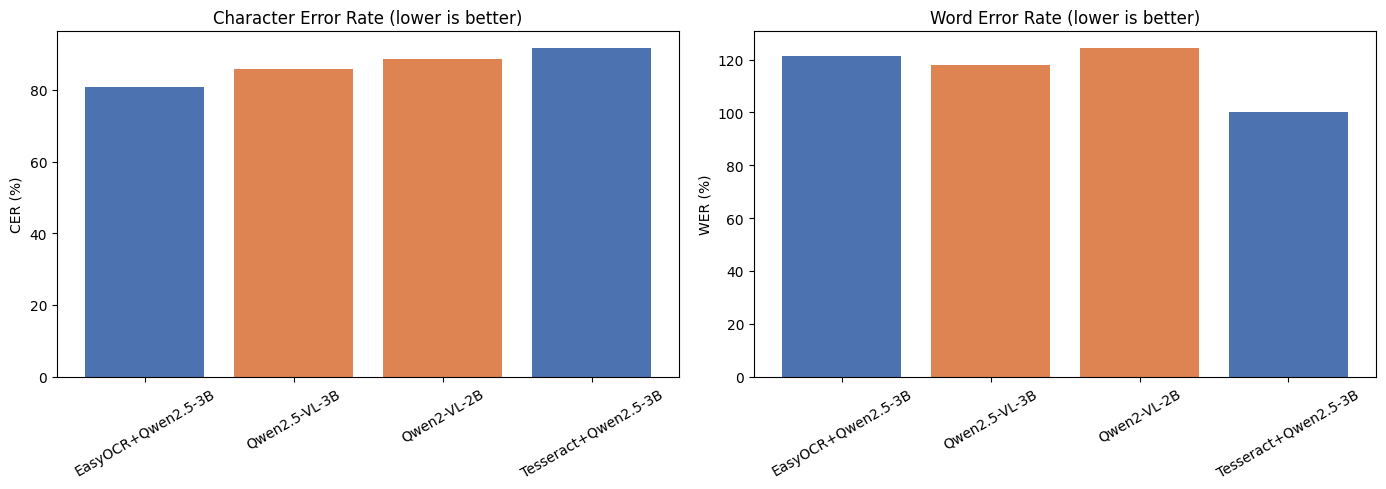

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#4C72B0' if a == 'OCR-LLM' else '#DD8452' for a in summary_df['Approach']]

axes[0].bar(summary_df['Model'], summary_df['CER (%)'], color=colors)
axes[0].set_title('Character Error Rate (lower is better)')
axes[0].set_ylabel('CER (%)')
axes[0].tick_params(axis='x', rotation=30)

axes[1].bar(summary_df['Model'], summary_df['WER (%)'], color=colors)
axes[1].set_title('Word Error Rate (lower is better)')
axes[1].set_ylabel('WER (%)')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'comparison_plot.png', dpi=120, bbox_inches='tight')
plt.show()
